# 03. Spatial-Spectral 2D-CNN: Alpha-Band Time-Frequency Classification
### Author: Md. Reazul Islam | Department of Computer Science & Engineering, North Western University / Prospective Fall 2027 M.S. Graduate Researcher
---
## 1. Neurophysiological Motivation & 2D Time-Frequency Mapping
The **Alpha frequency band (8–13 Hz)** represents posterior dominant resting-state cortical rhythms and thalamocortical synchronization. In patients with clinical epilepsy, focal spike-wave discharges and paroxysmal seizures lead to localized suppression, phase distortion, and power redistributions.

Rather than relying solely on 1D time-domain statistical moments, this pipeline converts multi-channel EEG signals into **2D Time-Frequency Spectrograms (100 × 100 pixels)** using Short-Time Fourier Transform (STFT), capturing simultaneous temporal evolution and spectral power densities across both Grayscale ( \times 100 \times 1$) and RGB ( \times 100 \times 3$) color representations.

## 2. 2D-CNN Model Architecture
The deep neural network utilizes a hierarchical feature extraction backbone:
- **Input Layer**:  \times 100$ spatial-spectral image (normalized to $[0, 1]$).
- **Conv Block 1**: 32 filters ( \times 3$), ReLU activation $\rightarrow$ Max Pooling ( \times 2$).
- **Conv Block 2**: 64 filters ( \times 3$), ReLU activation $\rightarrow$ Max Pooling ( \times 2$).
- **Conv Block 3**: 64 filters ( \times 3$), ReLU activation $\rightarrow$ Flatten layer.
- **Dense Classifier**: Fully connected layer (64 hidden units, ReLU) $\rightarrow$ Dropout / Softmax output (2 classes: Seizure-Positive vs. Healthy Control).


In [86]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import img_to_array, load_img
from sklearn.model_selection import train_test_split
import random

## 2. Spectrogram Data Loading & Normalization
Images are resized to  \times 100$ and partitioned into train, validation, and holdout test sets ($ train-test split with \%$ validation allocation).


In [87]:
def load_images_from_folder(folder):
    images = []
    for filename in os.listdir(folder):
        img = load_img(os.path.join(folder,filename), color_mode='grayscale', target_size=(img_height, img_width))
        img = img_to_array(img)
        images.append(img)
    return np.array(images)

In [88]:
img_height, img_width = 100, 100
num_classes = 2
epochs = 10
batch_size = 32


In [89]:
neg_images = load_images_from_folder("../data/spectrograms/alpha/neg")
pos_images = load_images_from_folder("../data/spectrograms/alpha/pos")

In [90]:
random.shuffle(neg_images)
random.shuffle(pos_images)

In [91]:
neg_labels = np.zeros(len(neg_images))
pos_labels = np.ones(len(pos_images))

In [92]:
X = np.concatenate((neg_images, pos_images), axis=0)
y = np.concatenate((neg_labels, pos_labels), axis=0)

In [93]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42)

In [94]:
X_train = X_train / 255.0
X_val = X_val / 255.0
X_test = X_test / 255.0

## 3. Deep 2D Convolutional Neural Network (CNN) Definition & Training
Constructing the 3-layer convolutional feature extractor with Adam optimizer and Sparse Categorical Crossentropy loss.


In [95]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(img_height, img_width, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

In [96]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [97]:
history = model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, validation_data=(X_val, y_val))

Epoch 1/10
1/1 [==============================] - 2s 2s/step - loss: 0.6960 - accuracy: 0.3333 - val_loss: 1.4999 - val_accuracy: 0.1429
Epoch 2/10
1/1 [==============================] - 0s 319ms/step - loss: 0.7161 - accuracy: 0.6667 - val_loss: 0.9749 - val_accuracy: 0.1429
Epoch 3/10
1/1 [==============================] - 0s 301ms/step - loss: 0.6417 - accuracy: 0.6667 - val_loss: 0.7853 - val_accuracy: 0.1429
Epoch 4/10
1/1 [==============================] - 0s 281ms/step - loss: 0.6617 - accuracy: 0.6667 - val_loss: 0.7772 - val_accuracy: 0.1429
Epoch 5/10
1/1 [==============================] - 0s 294ms/step - loss: 0.6633 - accuracy: 0.6667 - val_loss: 0.8207 - val_accuracy: 0.1429
Epoch 6/10
1/1 [==============================] - 0s 317ms/step - loss: 0.6540 - accuracy: 0.6667 - val_loss: 0.8835 - val_accuracy: 0.1429
Epoch 7/10
1/1 [==============================] - 0s 308ms/step - loss: 0.6452 - accuracy: 0.6667 - val_loss: 0.9670 - val_accuracy: 0.1429
Epoch 8/10
1/1 [=======

## 4. Empirical Evaluation: Training & Validation Convergence
Analyzing the 10-epoch training and validation accuracy trajectories.


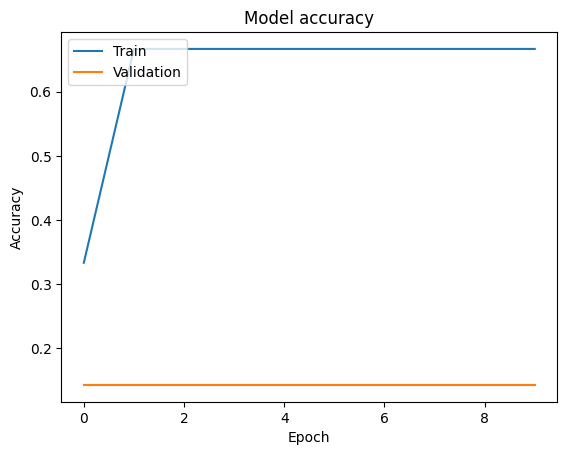

In [98]:
# Plot training & validation accuracy values
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()